## 1. DATA CLEANING

# 1.1 Data Loading

In [60]:
#import os
#os.chdir("/workspaces/ITBA")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("EVChargingStationUsage.csv", low_memory=False)
df.head()

,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,Longitude,Currency,Fee,Ended By,Plug In Event Id,Driver Postal Code,User ID,County,System S/N,Model Number
0,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/29/2011 20:17,PDT,7/29/2011 23:20,PDT,7/29/2011 23:20,3:03:32,1:54:03,...,-122.160309,USD,0.0,Plug Out at Vehicle,3,95124.0,3284,NaN,NaN,NaN
1,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 0:00,PDT,7/30/2011 0:02,PDT,7/30/2011 0:02,0:02:06,0:01:54,...,-122.160309,USD,0.0,Customer,4,94301.0,4169,NaN,NaN,NaN
2,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 8:16,PDT,7/30/2011 12:34,PDT,7/30/2011 12:34,4:17:32,4:17:28,...,-122.160309,USD,0.0,Plug Out at Vehicle,5,94301.0,4169,NaN,NaN,NaN
3,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 14:51,PDT,7/30/2011 16:55,PDT,7/30/2011 16:55,2:03:24,2:02:58,...,-122.160309,USD,0.0,Customer,6,94302.0,2545,NaN,NaN,NaN
4,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 18:51,PDT,7/30/2011 20:03,PDT,7/30/2011 20:03,1:11:24,0:43:54,...,-122.160309,USD,0.0,Plug Out at Vehicle,7,94043.0,3765,NaN,NaN,NaN


In [61]:
print("Rows and columns:", df.shape)
display(df.head())
df.info()

Rows and columns: (259415, 33)


,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,Longitude,Currency,Fee,Ended By,Plug In Event Id,Driver Postal Code,User ID,County,System S/N,Model Number
0,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/29/2011 20:17,PDT,7/29/2011 23:20,PDT,7/29/2011 23:20,3:03:32,1:54:03,...,-122.160309,USD,0.0,Plug Out at Vehicle,3,95124.0,3284,NaN,NaN,NaN
1,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 0:00,PDT,7/30/2011 0:02,PDT,7/30/2011 0:02,0:02:06,0:01:54,...,-122.160309,USD,0.0,Customer,4,94301.0,4169,NaN,NaN,NaN
2,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 8:16,PDT,7/30/2011 12:34,PDT,7/30/2011 12:34,4:17:32,4:17:28,...,-122.160309,USD,0.0,Plug Out at Vehicle,5,94301.0,4169,NaN,NaN,NaN
3,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 14:51,PDT,7/30/2011 16:55,PDT,7/30/2011 16:55,2:03:24,2:02:58,...,-122.160309,USD,0.0,Customer,6,94302.0,2545,NaN,NaN,NaN
4,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 18:51,PDT,7/30/2011 20:03,PDT,7/30/2011 20:03,1:11:24,0:43:54,...,-122.160309,USD,0.0,Plug Out at Vehicle,7,94043.0,3765,NaN,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 259415 entries, 0 to 259414
Data columns (total 33 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   Station Name                     259415 non-null  object 
 1   MAC Address                      259415 non-null  object 
 2   Org Name                         259415 non-null  object 
 3   Start Date                       259415 non-null  object 
 4   Start Time Zone                  259415 non-null  object 
 5   End Date                         259415 non-null  object 
 6   End Time Zone                    259415 non-null  object 
 7   Transaction Date (Pacific Time)  259206 non-null  object 
 8   Total Duration (hh:mm:ss)        259415 non-null  object 
 9   Charging Time (hh:mm:ss)         259415 non-null  object 
 10  Energy (kWh)                     259415 non-null  float64
 11  GHG Savings (kg)                 259415 non-null  float64
 12  Ga

# 1.2 Missing values

In [62]:
print(df.isnull().sum())
print(df.isnull().mean() * 100)

Station Name                           0
MAC Address                            0
Org Name                               0
Start Date                             0
Start Time Zone                        0
End Date                               0
End Time Zone                          0
Transaction Date (Pacific Time)      209
Total Duration (hh:mm:ss)              0
Charging Time (hh:mm:ss)               0
Energy (kWh)                           0
GHG Savings (kg)                       0
Gasoline Savings (gallons)             0
Port Type                              9
Port Number                            0
Plug Type                              0
EVSE ID                            78948
Address 1                              0
City                                   0
State/Province                         0
Postal Code                            0
Country                                0
Latitude                               0
Longitude                              0
Currency        

In [63]:
columns = [
    "EVSE ID",
    "Currency",
    "Transaction Date (Pacific Time)",
    "Port Type",
    "Energy (kWh)",
    "Start Date",
    "End Date"
]

df[columns].isnull().mean() * 100

EVSE ID                            30.433090
Currency                            0.689243
Transaction Date (Pacific Time)     0.080566
Port Type                           0.003469
Energy (kWh)                        0.000000
Start Date                          0.000000
End Date                            0.000000
dtype: float64

# 1.3 Duplicate Records

In [64]:
print("Duplicate rows:", df.duplicated().sum())
df[df.duplicated(keep=False)]

Duplicate rows: 4


,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,Longitude,Currency,Fee,Ended By,Plug In Event Id,Driver Postal Code,User ID,County,System S/N,Model Number
32433,PALO ALTO CA / MPL #6,000D6F00015B7509,City of Palo Alto,2/25/2015 15:24,PST,2/25/2015 15:46,PST,2/25/2015 15:46,0:22:23,0:22:10,...,-122.113457,USD,0.00,Plug Out at Vehicle,469,95134.0,318799,NaN,NaN,NaN
32434,PALO ALTO CA / MPL #6,000D6F00015B7509,City of Palo Alto,2/25/2015 15:24,PST,2/25/2015 15:46,PST,2/25/2015 15:46,0:22:23,0:22:10,...,-122.113457,USD,0.00,Plug Out at Vehicle,469,95134.0,318799,NaN,NaN,NaN
108235,PALO ALTO CA / HIGH #2,0024:B100:0002:5959,City of Palo Alto,2/27/2017 11:14,PST,2/27/2017 14:17,PST,2/27/2017 14:17,3:02:42,2:33:45,...,-122.163017,USD,0.00,Plug Out at Vehicle,1488222853,94301.0,738281,Santa Clara County,1.640410e+11,CT4020-HD
108236,PALO ALTO CA / HIGH #2,0024:B100:0002:5959,City of Palo Alto,2/27/2017 11:14,PST,2/27/2017 14:17,PST,2/27/2017 14:17,3:02:42,2:33:45,...,-122.163017,USD,0.00,Plug Out at Vehicle,1488222853,94301.0,738281,Santa Clara County,1.640410e+11,CT4020-HD
109966,PALO ALTO CA / BRYANT #2,000D:6F00:009D:CFC3,City of Palo Alto,3/10/2017 14:07,PST,3/10/2017 15:53,PST,3/10/2017 15:53,1:46:01,1:24:31,...,-122.162140,USD,0.00,Customer,9453,94065.0,548777,Santa Clara County,1.023100e+11,CT2100-HD-CCR
109967,PALO ALTO CA / BRYANT #2,000D:6F00:009D:CFC3,City of Palo Alto,3/10/2017 14:07,PST,3/10/2017 15:53,PST,3/10/2017 15:53,1:46:01,1:24:31,...,-122.162140,USD,0.00,Customer,9453,94065.0,548777,Santa Clara County,1.023100e+11,CT2100-HD-CCR
206764,PALO ALTO CA / BRYANT #5,0024:B100:0002:6D51,City of Palo Alto,4/29/2019 8:10,PDT,4/29/2019 9:09,PDT,4/29/2019 9:10,0:59:06,0:57:54,...,-122.162231,USD,1.33,Plug Out at Vehicle,3413,94027.0,4516921,Santa Clara County,1.707410e+11,CT4020-HD
206765,PALO ALTO CA / BRYANT #5,0024:B100:0002:6D51,City of Palo Alto,4/29/2019 8:10,PDT,4/29/2019 9:09,PDT,4/29/2019 9:10,0:59:06,0:57:54,...,-122.162231,USD,1.33,Plug Out at Vehicle,3413,94027.0,4516921,Santa Clara County,1.707410e+11,CT4020-HD


In [65]:
df = df.drop_duplicates()
print(df.duplicated().sum())

0


# 1.4 Energy Validation

In [66]:
df["Energy (kWh)"].describe()

count    259411.000000
mean          8.544332
std           7.185497
min           0.010000
25%           3.784000
50%           6.868920
75%          11.458754
max          97.360000
Name: Energy (kWh), dtype: float64

In [67]:
(df["Energy (kWh)"] < 0).sum()

np.int64(0)

# 1.5 Duration Validation

In [68]:
df["Total Hours"] = pd.to_timedelta(df["Total Duration (hh:mm:ss)"]).dt.total_seconds() / 3600
df["Charging Hours"] = pd.to_timedelta(df["Charging Time (hh:mm:ss)"]).dt.total_seconds() / 3600
df[["Total Hours", "Charging Hours"]].describe()

,Total Hours,Charging Hours
count,259411.000000,259411.000000
mean,2.486835,1.999134
std,2.212672,1.382588
min,0.016667,0.001667
25%,1.170833,1.040000
50%,2.089167,1.816389
75%,3.090139,2.697222
max,114.539167,22.931944


In [69]:
print((df["Total Hours"] <= 0).sum())
print((df["Charging Hours"] <= 0).sum())
print((df["Charging Hours"] > df["Total Hours"]).sum())

0
0
45


45 records will be removed because their charging duration exceeded their total connection duration.

In [70]:
df = df[df["Charging Hours"] <= df["Total Hours"]]
print((df["Charging Hours"] > df["Total Hours"]).sum())

0


Outliers were not removed at this stage, since long sessions may reflect real behaviour (e.g. vehicles left plugged in overnight). Extreme users will be handled during clustering, where DBSCAN can identify them as noise.

# 1.6 Date Validation

In [71]:
df["Start Date"] = pd.to_datetime(df["Start Date"], format="mixed", errors="coerce")

In [72]:
s = df["End Date"].astype(str)
numbers = pd.to_numeric(s, errors="coerce")

df["End Date"] = pd.to_datetime(
    s, format="mixed", errors="coerce"
)

mask = numbers.notna()

df["End Date"] = df["End Date"].mask(
    mask,
    pd.to_datetime(
        numbers, unit="D",
        origin="1899-12-30",
        errors="coerce"
    )
)

In [73]:
print(df[["Start Date", "End Date"]].isnull().sum())

Start Date    0
End Date      0
dtype: int64


In [74]:
print((df["End Date"] < df["Start Date"]).sum())

31


31 records have been found where the End Date was earlier than the Start Date and they will be removed.

In [75]:
df = df.dropna(subset=["Start Date", "End Date"])
df = df[df["End Date"] >= df["Start Date"]]

In [76]:
print(df["Start Date"].dt.year.value_counts().sort_index())
print("Earliest start:", df["Start Date"].min())
print("Latest end:", df["End Date"].max())

Start Date
2011     1274
2012     6600
2013    10097
2014    11712
2015    23104
2016    46930
2017    48990
2018    42803
2019    47731
2020    20094
Name: count, dtype: int64
Earliest start: 2011-07-29 20:17:00
Latest end: 2021-01-04 21:01:00


All dates fall between 2011 and 2020, so no further date corrections were needed.

# 1.7 ID Validation

In [77]:
df["User ID"] = pd.to_numeric(df["User ID"], errors="coerce").astype("Int64")
print("Unique users:", df["User ID"].nunique())

Unique users: 21418


User ID contained mixed types, so the same user could appear as two different IDs. We converted all IDs to integers; 41 non-numeric values could not be converted and were treated as missing.

In [78]:
id_columns = ["User ID", "EVSE ID", "Plug In Event Id"]
df[id_columns].isnull().sum()

User ID              7712
EVSE ID             78912
Plug In Event Id        0
dtype: int64

In [79]:
print(df[id_columns].nunique())
df["User ID"].isna().mean() * 100

User ID             21418
EVSE ID                51
Plug In Event Id    36828
dtype: int64


np.float64(2.973759808741589)

Some User IDs (2.97%) and EVSE IDs are missing. We will keep these to avoid losing useful data. Rows without user ID will not be used for clustering.

# 1.8 Categorical Variables

In [80]:
#df.select_dtypes(include=["object", "str", "category"]).columns

df.select_dtypes(include=["object", "category"]).columns

Index(['Station Name', 'MAC Address', 'Org Name', 'Start Time Zone',
       'End Time Zone', 'Transaction Date (Pacific Time)',
       'Total Duration (hh:mm:ss)', 'Charging Time (hh:mm:ss)', 'Port Type',
       'Plug Type', 'Address 1', 'City', 'State/Province', 'Country',
       'Currency', 'Ended By', 'County', 'Model Number'],
      dtype='object')

In [81]:
for col in ["Port Type", "Plug Type", "Currency", "Ended By"]:
    print(col, df[col].isna().sum())

Port Type 1
Plug Type 0
Currency 1785
Ended By 246


In [82]:
for col in ["Port Type", "Currency", "Ended By"]:
    df[col] = df[col].fillna("Unknown")

In [83]:
df[["Port Type", "Currency", "Ended By"]].isna().sum()

Port Type    0
Currency     0
Ended By     0
dtype: int64

Categorical columns have been checked for missing values. Missing values in Port Type, Currency, and Ended By were replaced with "Unknown". No rows were removed.

# 1.9 Different scales

In [84]:
df.select_dtypes(include="number").describe()

,Energy (kWh),GHG Savings (kg),Gasoline Savings (gallons),Port Number,EVSE ID,Postal Code,Latitude,Longitude,Fee,Plug In Event Id,Driver Postal Code,User ID,System S/N,Total Hours,Charging Hours
count,259335.000000,259335.000000,259335.000000,259335.000000,1.804230e+05,259335.000000,259335.000000,259335.000000,259335.000000,2.593350e+05,250947.000000,251623.0,1.804230e+05,259335.000000,259335.000000
mean,8.542384,3.587801,1.072068,1.591656,1.463122e+05,94302.315966,37.439564,-122.151264,1.096791,1.188481e+08,94170.237409,1400398.123701,1.443815e+11,2.487030,1.998667
std,7.178741,3.015071,0.900933,0.491528,2.429933e+05,1.941763,0.009621,0.015382,1.924099,4.057448e+08,4250.389497,3606617.443068,2.483270e+10,2.212791,1.381493
min,0.010000,0.004000,0.001000,1.000000,3.792000e+03,94301.000000,37.422104,-122.163239,0.000000,1.000000e+00,1013.000000,0.0,1.023100e+11,0.016667,0.001667
25%,3.784438,1.589000,0.475000,1.000000,4.358300e+04,94301.000000,37.428318,-122.162170,0.000000,1.573000e+03,94087.000000,213037.0,1.231100e+11,1.171111,1.040000
50%,6.868316,2.885000,0.862000,2.000000,1.074270e+05,94301.000000,37.444489,-122.158272,0.000000,3.573000e+03,94304.000000,463301.0,1.427410e+11,2.089444,1.816389
75%,11.457716,4.812000,1.438000,2.000000,1.745590e+05,94303.000000,37.446613,-122.145699,1.640000,6.340000e+03,94804.000000,784343.0,1.705410e+11,3.090278,2.697222
max,97.360000,40.891000,12.219000,2.000000,5.535441e+06,94306.000000,37.449375,-122.112480,84.560000,1.609436e+09,99354.000000,23137801.0,2.002410e+11,114.539167,22.931944


The numerical columns have different scales. We did not apply scaling because it will be done later for clustering.

# 1.10 Cleaned Dataset

In [85]:
df.to_csv("cleaned_data.csv", index=False)

# 2. EXPLORATORY DATA ANALYSIS

# 2.1 Time Features

In [86]:
df["Hour"] = df["Start Date"].dt.hour
df["Weekday"] = df["Start Date"].dt.dayofweek
df["Month"] = df["Start Date"].dt.to_period("M")
df["Year"] = df["Start Date"].dt.year
df["Is Weekend"] = df["Weekday"] >= 5
df["Idle Hours"] = df["Total Hours"] - df["Charging Hours"]

# 2.2 Usage Over Time

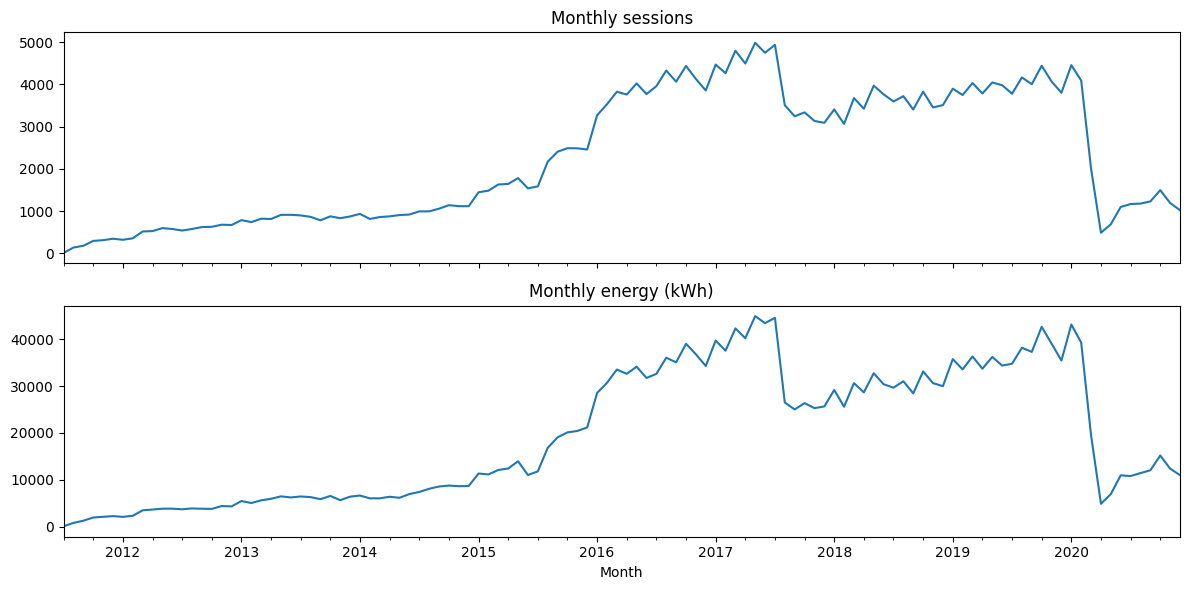

In [87]:
monthly = df.groupby("Month").agg(sessions=("Energy (kWh)", "size"),
                                  energy=("Energy (kWh)", "sum"))
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
monthly["sessions"].plot(ax=ax[0], title="Monthly sessions")
monthly["energy"].plot(ax=ax[1], title="Monthly energy (kWh)")
plt.tight_layout(); plt.show()

Usage grew steadily until mid-2017, dropped when fees were introduced, and fell sharply in March 2020 due to COVID-19. Since the test set covers the last 30% of the data, it will include this unusual COVID period.

# 2.3 Charging Patterns by Hour and Weekday

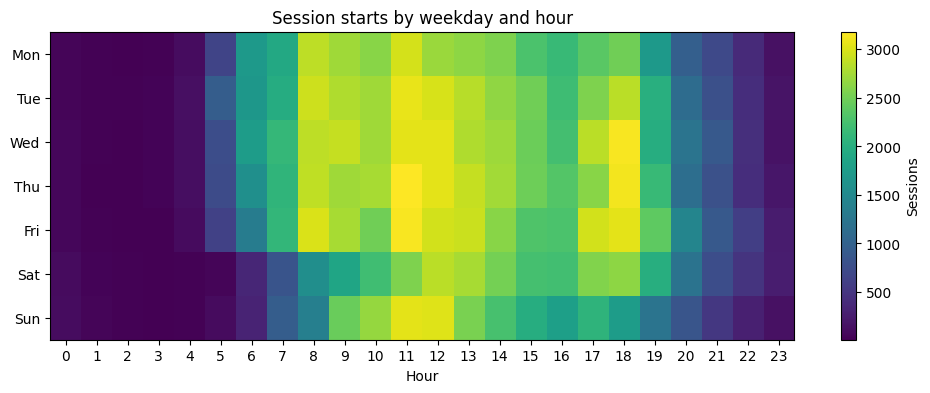

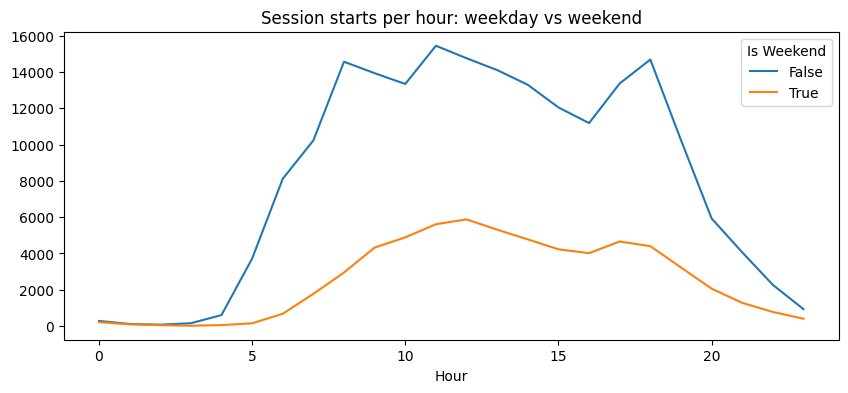

In [88]:
pivot = df.pivot_table(index="Weekday", columns="Hour",
                       values="Energy (kWh)", aggfunc="size")
plt.figure(figsize=(12, 4))
plt.imshow(pivot, aspect="auto", cmap="viridis")
plt.yticks(range(7), ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])
plt.xticks(range(24)); plt.colorbar(label="Sessions")
plt.title("Session starts by weekday and hour"); plt.xlabel("Hour"); plt.show()

df.groupby(["Is Weekend", "Hour"]).size().unstack(0).plot(
    figsize=(10, 4), title="Session starts per hour: weekday vs weekend")
plt.show()

Weekdays have much more activity than weekends, with peaks around 8 am, noon and 5–6 pm, while weekends show a flatter profile peaking around noon. This supports using hour and weekday as features for clustering and prediction.

# 2.4 Energy and Duration Distributions

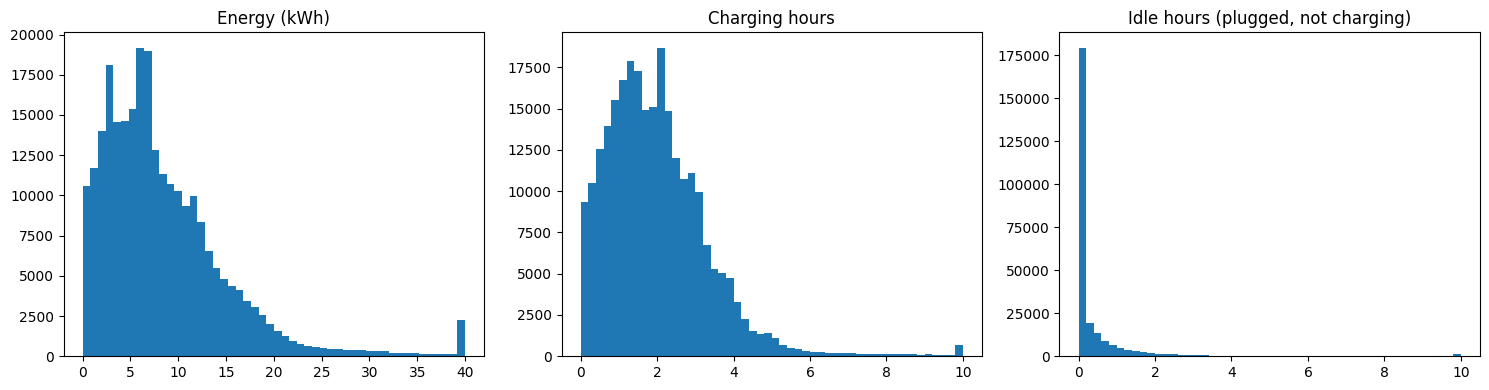

        Energy (kWh)  Charging Hours     Idle Hours
count  259335.000000   259335.000000  259335.000000
mean        8.542384        1.998667       0.488362
std         7.178741        1.381493       1.479172
min         0.010000        0.001667       0.000000
25%         3.784438        1.040000       0.003889
50%         6.868316        1.816389       0.007222
75%        11.457716        2.697222       0.354722
max        97.360000       22.931944     112.547222


In [89]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(df["Energy (kWh)"].clip(upper=40), bins=50); ax[0].set_title("Energy (kWh)")
ax[1].hist(df["Charging Hours"].clip(upper=10), bins=50); ax[1].set_title("Charging hours")
ax[2].hist(df["Idle Hours"].clip(upper=10), bins=50); ax[2].set_title("Idle hours (plugged, not charging)")
plt.tight_layout(); plt.show()
print(df[["Energy (kWh)", "Charging Hours", "Idle Hours"]].describe())

All three variables are right-skewed: most sessions use 2–12 kWh and charge for under 4 hours. Most sessions have almost no idle time, but a long tail of vehicles stays plugged in for many hours after charging ends.

# 2.5 Station Analysis

Number of stations: 47


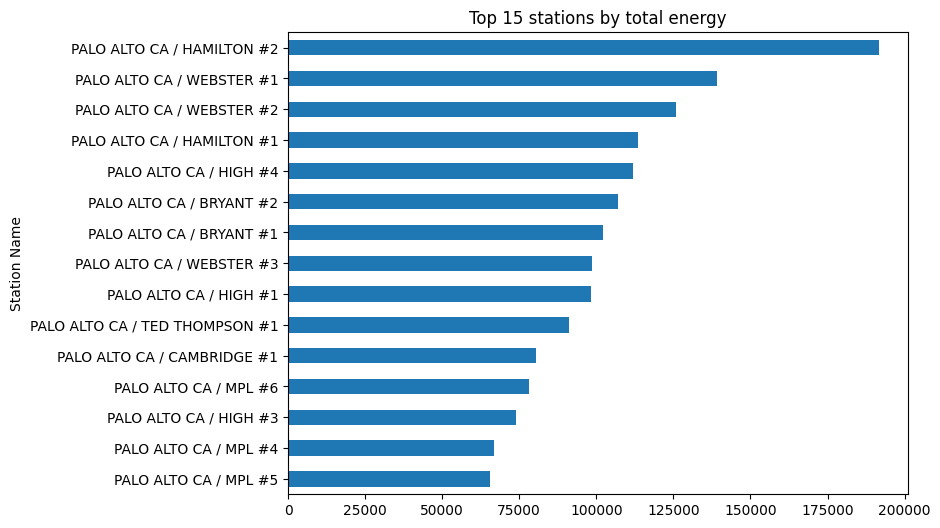

In [90]:
station = df.groupby("Station Name").agg(sessions=("Energy (kWh)", "size"),
                                         energy=("Energy (kWh)", "sum"),
                                         avg_idle=("Idle Hours", "mean"))
print("Number of stations:", len(station))
station.sort_values("energy", ascending=False).head(15)["energy"].plot.barh(
    figsize=(8, 6), title="Top 15 stations by total energy")
plt.gca().invert_yaxis(); plt.show()

Demand is uneven across stations, with HAMILTON #2 having by far the highest total energy. Totals also depend on how long each station has been active.

# 2.6 User Analysis

count    21418.000000
mean        11.748202
std         44.829854
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max       1115.000000
dtype: float64
Users with only 1 session: 43.67821458586236 %


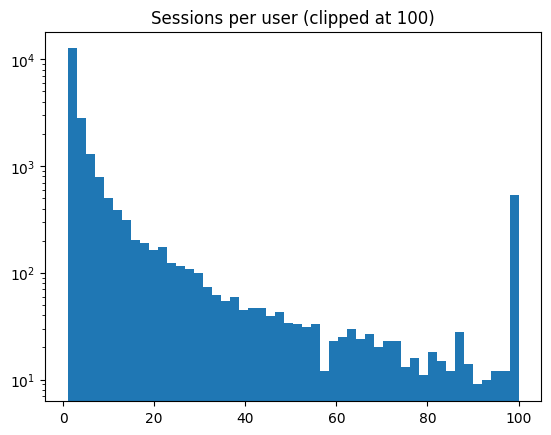

In [91]:
user_sessions = df.dropna(subset=["User ID"]).groupby("User ID").size()
print(user_sessions.describe())
print("Users with only 1 session:", (user_sessions == 1).mean() * 100, "%")
plt.hist(user_sessions.clip(upper=100), bins=50)
plt.title("Sessions per user (clipped at 100)"); plt.yscale("log"); plt.show()

43.7% of users charged only once and half of the users charged at most 2 times, while the most active user had 1,115 sessions. Only users with a minimum number of sessions will be included in the clustering.

# 2.7 Idle Time (Hoarding) and Fees

Share of sessions with >1h idle: 12.072030385408834 %


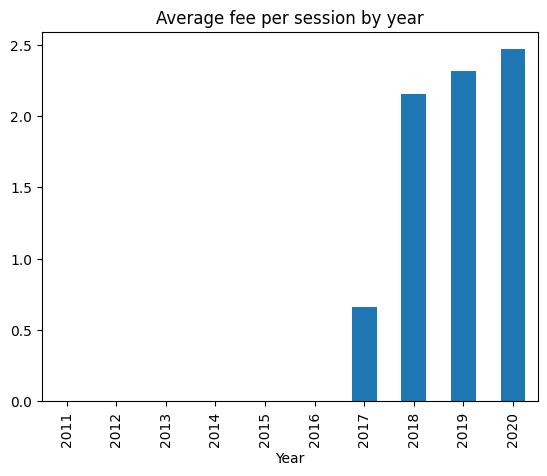

In [92]:
print("Share of sessions with >1h idle:", (df["Idle Hours"] > 1).mean() * 100, "%")
df.groupby("Year")["Fee"].mean().plot.bar(title="Average fee per session by year")
plt.show()

About 12% of sessions have more than 1 hour of idle time ("hoarding"). Charging was free until 2017, after which the average fee rose to about 2.5 USD per session by 2020.

## 3. HOURLY AGGREGATION
The mandatory tasks require energy demand at a one hour resolution per station, but the raw data is session based. A single session can start at 20:17 and finish at 22:11, so it contributes to three different hours. This section converts the session level table into an hourly table.

Two quantities are produced per station and hour:

- **Hourly energy (kWh)**, the energy delivered during that hour
- **Occupied port hours**, how much of that hour the station's ports were taken

Energy is spread over the charging window only, because no energy flows once the car is full. Occupancy is spread over the full plug in window, because a port that is still plugged in is unavailable to other drivers even when charging has finished.

# 3.1 Charging end time

In [93]:
df["Charge End"] = df["Start Date"] + pd.to_timedelta(df["Charging Hours"], unit="h")
df[["Start Date", "Charging Hours", "Charge End"]].head()

,Start Date,Charging Hours,Charge End
0,2011-07-29 20:17:00,1.900833,2011-07-29 22:11:02.999999998
1,2011-07-30 00:00:00,0.031667,2011-07-30 00:01:54.000000001
2,2011-07-30 08:16:00,4.291111,2011-07-30 12:33:27.999999999
3,2011-07-30 14:51:00,2.049444,2011-07-30 16:53:57.999999998
4,2011-07-30 18:51:00,0.731667,2011-07-30 19:34:54.000000001


The dataset records when a session started and when the car was unplugged, but not when charging itself stopped. That moment is the start time plus the charging duration and it is needed to allocate energy correctly.

# 3.2 Expanding sessions into hours

In [94]:
def expand_to_hours(data, start_col, end_col):
    out = data[["Station Name", start_col, end_col]].copy()

    out["First Hour"] = out[start_col].dt.floor("h")
    span = (out[end_col].dt.ceil("h") - out["First Hour"]).dt.total_seconds() / 3600
    out["Hours Touched"] = span.clip(lower=1).astype(int)

    out = out.loc[np.repeat(out.index.to_numpy(), out["Hours Touched"].to_numpy())].copy()
    out["Hour"] = out["First Hour"] + pd.to_timedelta(out.groupby(level=0).cumcount(), unit="h")

    lo = np.maximum(out["Hour"], out[start_col])
    hi = np.minimum(out["Hour"] + pd.Timedelta(hours=1), out[end_col])
    out["Overlap Hours"] = (hi - lo).dt.total_seconds().clip(lower=0) / 3600

    return out

Each session is repeated once for every hour it touches, and for each copy the overlap with that hour is measured in hours.

For a session running from 20:17 to 22:11 this gives three rows: 0.72 hours in the 20:00 hour, a full hour in the 21:00 hour, and 0.18 hours in the 22:00 hour. The same expansion is reused for energy and for occupancy, only the interval passed in changes.

# 3.3 Hourly energy per station

In [95]:
energy = expand_to_hours(df, "Start Date", "Charge End")
energy["Session Energy"] = df["Energy (kWh)"].reindex(energy.index).to_numpy()

total_overlap = energy.groupby(level=0)["Overlap Hours"].transform("sum")
energy["Hourly Energy (kWh)"] = (
    energy["Session Energy"] * energy["Overlap Hours"] / total_overlap.where(total_overlap > 0, 1)
)

hourly_energy = energy.groupby(["Station Name", "Hour"], as_index=False)["Hourly Energy (kWh)"].sum()
print("Hourly energy rows:", hourly_energy.shape)

Hourly energy rows: (579206, 3)


Energy is split between hours in proportion to the share of the charging time that fell in each hour. This assumes a constant charging rate within a session, which is a simplification, but the dataset holds no charging curve so a finer assumption is not supported by the data.

In [96]:
print("Session total:", df["Energy (kWh)"].sum())
print("Hourly total: ", hourly_energy["Hourly Energy (kWh)"].sum())

Session total: 2215339.084834
Hourly total:  2215339.0848339996


The two totals match, which confirms the allocation neither creates nor destroys energy.

# 3.4 Hourly occupancy per station

In [97]:
occupancy = expand_to_hours(df, "Start Date", "End Date")
occupancy = occupancy.rename(columns={"Overlap Hours": "Occupied Port Hours"})

hourly_occupancy = occupancy.groupby(["Station Name", "Hour"], as_index=False)["Occupied Port Hours"].sum()
print("Hourly occupancy rows:", hourly_occupancy.shape)
print("Maximum occupied port hours in a single hour:", hourly_occupancy["Occupied Port Hours"].max())

Hourly occupancy rows: (664344, 3)
Maximum occupied port hours in a single hour: 7.0


Occupancy is measured over the full plug in window and is not rescaled, so the value is the number of port hours taken at that station during that hour. Stations with several ports can therefore exceed one, and the observed maximum of seven is consistent with the largest sites in the dataset.

# 3.5 Complete hourly grid

In [98]:
hours = pd.date_range(df["Start Date"].min().floor("h"), df["End Date"].max().ceil("h"), freq="h")
stations = df["Station Name"].unique()

grid = pd.MultiIndex.from_product([stations, hours], names=["Station Name", "Hour"]).to_frame(index=False)

hourly = (
    grid.merge(hourly_energy, on=["Station Name", "Hour"], how="left")
        .merge(hourly_occupancy, on=["Station Name", "Hour"], how="left")
)
hourly[["Hourly Energy (kWh)", "Occupied Port Hours"]] = hourly[["Hourly Energy (kWh)", "Occupied Port Hours"]].fillna(0.0)

del grid, occupancy, hourly_occupancy

print("Stations:", len(stations))
print("Hours:", len(hours))
print("Rows and columns:", hourly.shape)
hourly.head()

Stations: 47
Hours: 82731
Rows and columns: (3888357, 4)


,Station Name,Hour,Hourly Energy (kWh),Occupied Port Hours
0,PALO ALTO CA / HAMILTON #1,2011-07-29 20:00:00,2.356218,0.716667
1,PALO ALTO CA / HAMILTON #1,2011-07-29 21:00:00,3.287746,1.000000
2,PALO ALTO CA / HAMILTON #1,2011-07-29 22:00:00,0.605493,1.000000
3,PALO ALTO CA / HAMILTON #1,2011-07-29 23:00:00,0.000000,0.333333
4,PALO ALTO CA / HAMILTON #1,2011-07-30 00:00:00,0.106588,0.033333


The two tables above only contain hours in which something happened. A forecasting model needs a continuous series, and an hour with no sessions is a real observation of zero demand rather than missing data, so the full station by hour grid is built and the gaps are filled with zeros.

# 3.6 Saving the hourly dataset

In [99]:
hourly.to_csv("hourly_data.csv", index=False)

The hourly grid is written out so the prediction task can start from this file instead of rerunning the transformation.

# 4. TASK 1: USER CLUSTERING

# 4.1 Hourly energy per user
The clustering is done on users, so we reuse the hourly energy expansion from Section 3.3 and attach the User ID of each session. Rows without a User ID are excluded.

In [ ]:
#THIS PART HAS ERRORS!!

user_hourly = energy[["Hour", "Hourly Energy (kWh)"]].copy()
user_hourly["User ID"] = df["User ID"].reindex(energy.index).to_numpy()
user_hourly = user_hourly.dropna(subset=["User ID"])

del energy

print("User hourly rows:", len(user_hourly))
user_hourly.head()


KeyError: "['Hourly Energy (kWh)'] not in index"

# 4.1 Hourly energy and occupation per user

In [106]:
# HOURLY ENERGY PER USER
user_energy = expand_to_hours(df, "Start Date", "Charge End")
user_energy["Session Energy"] = (df["Energy (kWh)"].reindex(user_energy.index).to_numpy())
user_energy["User ID"] = (df["User ID"].reindex(user_energy.index).to_numpy())

# Calculate how many hours of charging each session
total_overlap = (
    user_energy.groupby(level=0)["Overlap Hours"]
    .transform("sum")
)

# Allocate session energy proportionally to each hour.
user_energy["Hourly Energy (kWh)"] = (
    user_energy["Session Energy"]
    * user_energy["Overlap Hours"]
    / total_overlap.where(total_overlap > 0, 1)
)
user_energy = user_energy.dropna(subset=["User ID"])

# Aggregate energy by user and hour.
user_energy_hourly = (
    user_energy
    .groupby(["User ID", "Hour"], as_index=False)
    ["Hourly Energy (kWh)"]
    .sum()
)


# HOURLY OCCUPATION PER USER
user_occupancy = expand_to_hours(df, "Start Date", "End Date")
user_occupancy["User ID"] = (df["User ID"].reindex(user_occupancy.index).to_numpy())
user_occupancy = user_occupancy.dropna(subset=["User ID"])

# Occupation is the time spent plugged in, including idle time after charging finishes.
user_occupancy = user_occupancy.rename(columns={"Overlap Hours": "Occupied Port Hours"})

# Aggregate occupation by user and hour.
user_occupancy_hourly = (
    user_occupancy
    .groupby(["User ID", "Hour"], as_index=False)
    ["Occupied Port Hours"]
    .sum()
)

# ENERGY AND OCCUPATION

user_hourly = pd.merge(
    user_energy_hourly,
    user_occupancy_hourly,
    on=["User ID", "Hour"],
    how="outer"
)

user_hourly[["Hourly Energy (kWh)", "Occupied Port Hours"]] = user_hourly[["Hourly Energy (kWh)", "Occupied Port Hours"]].fillna(0)


# ==================================================
# D. CHECK RESULTS
# ==================================================

print("Hourly records:", len(user_hourly))
print("Unique users:", user_hourly["User ID"].nunique())

print(
    "Total hourly energy:",
    user_hourly["Hourly Energy (kWh)"].sum()
)

print(
    "Total occupied port hours:",
    user_hourly["Occupied Port Hours"].sum()
)

display(user_hourly.head())


Hourly records: 884583
Unique users: 21418
Total hourly energy: 2143378.284543
Total occupied port hours: 647129.9294133331


,User ID,Hour,Hourly Energy (kWh),Occupied Port Hours
0,0.0,2011-08-02 12:00:00,1.968956,0.566667
1,0.0,2011-08-02 13:00:00,1.547175,0.450000
2,0.0,2011-08-04 20:00:00,2.315001,0.783333
3,0.0,2011-08-04 21:00:00,2.955320,1.000000
4,0.0,2011-08-04 22:00:00,2.955320,1.000000


# 4.2 User Features
For each user we create features that describe their charging behaviour: when they charge (share of energy at night, morning, afternoon and evening, and on weekends), how much and how long they charge, how long they stay plugged in after charging, and how many stations they use. Only users with at least 5 sessions are kept, since users with fewer sessions do not have a clear usage pattern.

In [107]:
user_hourly["Period"] = pd.cut(user_hourly["Hour"].dt.hour, bins=[0, 6, 12, 18, 24], right=False,
                               labels=["Night", "Morning", "Afternoon", "Evening"])
user_hourly["Weekend"] = user_hourly["Hour"].dt.dayofweek >= 5

period_share = user_hourly.pivot_table(index="User ID", columns="Period", values="Hourly Energy (kWh)",
                                       aggfunc="sum", observed=False)
period_share = period_share.div(period_share.sum(axis=1), axis=0)

total_energy = user_hourly.groupby("User ID")["Hourly Energy (kWh)"].sum()
weekend_energy = user_hourly[user_hourly["Weekend"]].groupby("User ID")["Hourly Energy (kWh)"].sum()
weekend_share = (weekend_energy / total_energy).fillna(0).rename("Weekend")

In [121]:
print("Session stats:", session_stats.shape)
print("Period share:", period_share.shape)
print("Weekend share:", weekend_share.shape)

Session stats: (21418, 5)
Period share: (21418, 4)
Weekend share: (21418, 1)


In [ ]:
print(type(session_stats.columns))
print(type(period_share.columns))
print(type(weekend_share.columns))

session_stats.columns = pd.Index(session_stats.columns.astype(str))
period_share.columns = pd.Index(period_share.columns.astype(str))

if isinstance(weekend_share, pd.DataFrame):
    weekend_share.columns = pd.Index(weekend_share.columns.astype(str))
    
# changing the types from class CategoricalIndex to Index

<class 'pandas.core.indexes.base.Index'>
<class 'pandas.core.indexes.category.CategoricalIndex'>
<class 'pandas.core.indexes.base.Index'>


In [129]:
session_stats = df.dropna(subset=["User ID"]).groupby("User ID").agg(
    Sessions=("Energy (kWh)", "size"),
    Avg_Energy=("Energy (kWh)", "mean"),
    Avg_Charging_Hours=("Charging Hours", "mean"),
    Avg_Idle_Hours=("Idle Hours", "mean"),
    Stations_Used=("Station Name", "nunique"))

users = session_stats.join(period_share)
users = users.join(weekend_share)
users.columns = [str(c) for c in users.columns]
users = users[users["Sessions"] >= 5]

print("Users kept for clustering:", len(users))
users.describe()

Users kept for clustering: 5975


,Sessions,Avg_Energy,Avg_Charging_Hours,Avg_Idle_Hours,Stations_Used,Night,Morning,Afternoon,Evening,Weekend_Share
count,5975.000000,5975.000000,5975.000000,5975.000000,5975.000000,5975.000000,5975.000000,5975.000000,5975.000000,5975.000000
mean,37.852218,7.779461,1.732436,0.339775,5.793640,0.014297,0.222658,0.458590,0.304456,0.302968
std,79.103764,5.246157,0.914811,0.627115,3.545122,0.061180,0.241199,0.248035,0.276892,0.288418
min,5.000000,0.019714,0.005278,0.001667,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7.000000,4.475895,1.128181,0.026022,3.000000,0.000000,0.025555,0.266883,0.046141,0.016949
50%,13.000000,6.556714,1.546128,0.147889,5.000000,0.000000,0.142255,0.451469,0.240275,0.241152
75%,31.000000,9.539276,2.119911,0.393366,7.000000,0.000000,0.339917,0.641125,0.503712,0.502536
max,1115.000000,56.407302,9.595302,10.646911,32.000000,0.836317,1.000000,1.000000,1.000000,1.000000


5,975 users have at least 5 sessions and are used for clustering. The time-of-day and weekend features are shares between 0 and 1, while the other features have different scales, so the data will be scaled before clustering.

# 4.3 Scaling
The features have very different scales (e.g. number of sessions vs. shares between 0 and 1), so they are standardized to have mean 0 and standard deviation 1. Sessions and idle hours are strongly right-skewed, so we first apply a log transformation to reduce the effect of extreme users.

In [139]:
from sklearn.preprocessing import StandardScaler

features = users.dropna().copy()
features["Sessions"] = np.log1p(features["Sessions"])
features["Avg_Idle_Hours"] = np.log1p(features["Avg_Idle_Hours"])

scaler = StandardScaler()
X = scaler.fit_transform(features)

print("Shape:", X.shape)
pd.DataFrame(X, columns=features.columns).describe().round(2)

Shape: (5975, 10)


,Sessions,Avg_Energy,Avg_Charging_Hours,Avg_Idle_Hours,Stations_Used,Night,Morning,Afternoon,Evening,Weekend_Share
count,5975.00,5975.00,5975.00,5975.00,5975.00,5975.00,5975.00,5975.00,5975.00,5975.00
mean,0.00,-0.00,0.00,0.00,-0.00,-0.00,0.00,-0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.07,-1.48,-1.89,-0.79,-1.35,-0.23,-0.92,-1.85,-1.10,-1.05
25%,-0.80,-0.63,-0.66,-0.71,-0.79,-0.23,-0.82,-0.77,-0.93,-0.99
50%,-0.26,-0.23,-0.20,-0.33,-0.22,-0.23,-0.33,-0.03,-0.23,-0.21
75%,0.53,0.34,0.42,0.32,0.34,-0.23,0.49,0.74,0.72,0.69
max,3.93,9.27,8.60,7.52,7.39,13.44,3.22,2.18,2.51,2.42


After scaling, all features have a mean of 0 and a standard deviation of 1, so no single feature dominates the clustering.

# 4.4 K-means
We run K-means for different numbers of clusters (k = 2 to 10) and use the elbow method (inertia) and the silhouette score to choose the number of clusters.

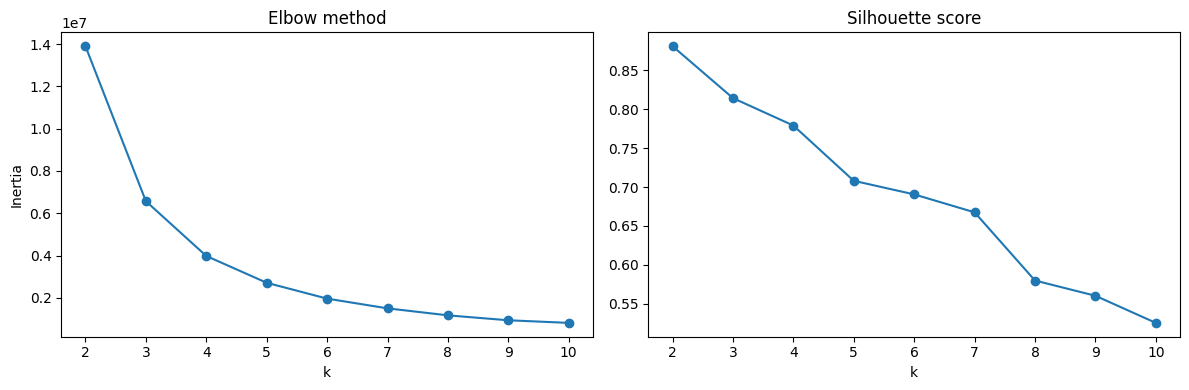

In [155]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 11)
inertias = []
silhouettes = []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X, labels, sample_size=5000, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_values, inertias, marker="o"); ax[0].set_title("Elbow method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia")
ax[1].plot(k_values, silhouettes, marker="o"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

We choose k = 2 because it has the highest silhouette score.

In [156]:
k = 2

kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
features["KMeans Cluster"] = kmeans.fit_predict(X)

print(features["KMeans Cluster"].value_counts().sort_index())
users.loc[features.index].groupby(features["KMeans Cluster"]).mean().round(2)

TypeError: list indices must be integers or slices, not str

The table shows the average feature values of each cluster, which we use to describe the user groups.

In [ ]:
#!pip install seaborn
#if you need to run it and you dont have it installed

In [154]:
k=3

kmeans3 = KMeans(n_clusters=3, n_init=10, random_state=42)
features["KMeans Cluster 3"] = kmeans3.fit_predict(X)

print(features["KMeans Cluster 3"].value_counts().sort_index())
users.loc[features.index].groupby(features["KMeans Cluster 3"]).mean().round(2)

TypeError: list indices must be integers or slices, not str

With k = 3 we find three user groups: regular weekday commuters (cluster 0), a small group of heavy evening and night users who stay plugged in long after charging ends (cluster 1), and occasional users who charge mostly in the afternoon, evening and on weekends (cluster 2).

## KMeans Heatmap

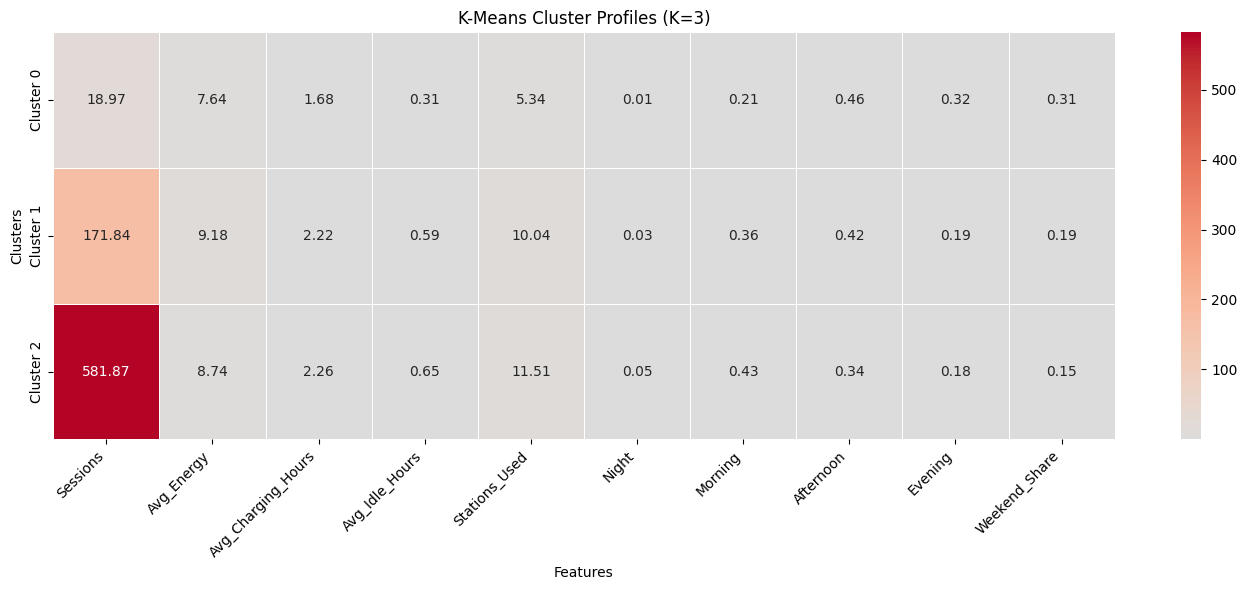

In [161]:
import matplotlib.pyplot as plt
import seaborn as sns

features = [
    "Sessions",
    "Avg_Energy",
    "Avg_Charging_Hours",
    "Avg_Idle_Hours",
    "Stations_Used",
    "Night",
    "Morning",
    "Afternoon",
    "Evening",
    "Weekend_Share"
]


X = users[features].copy()

cluster_centres = pd.DataFrame(
    kmeans3.cluster_centers_,
    columns=X.columns,
    index=["Cluster 0", "Cluster 1", "Cluster 2"]
)


plt.figure(figsize=(14, 6))
sns.heatmap(
    cluster_centres,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)
plt.title("K-Means Cluster Profiles (K=3)")
plt.xlabel("Features")
plt.ylabel("Clusters")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Standardized heatmap

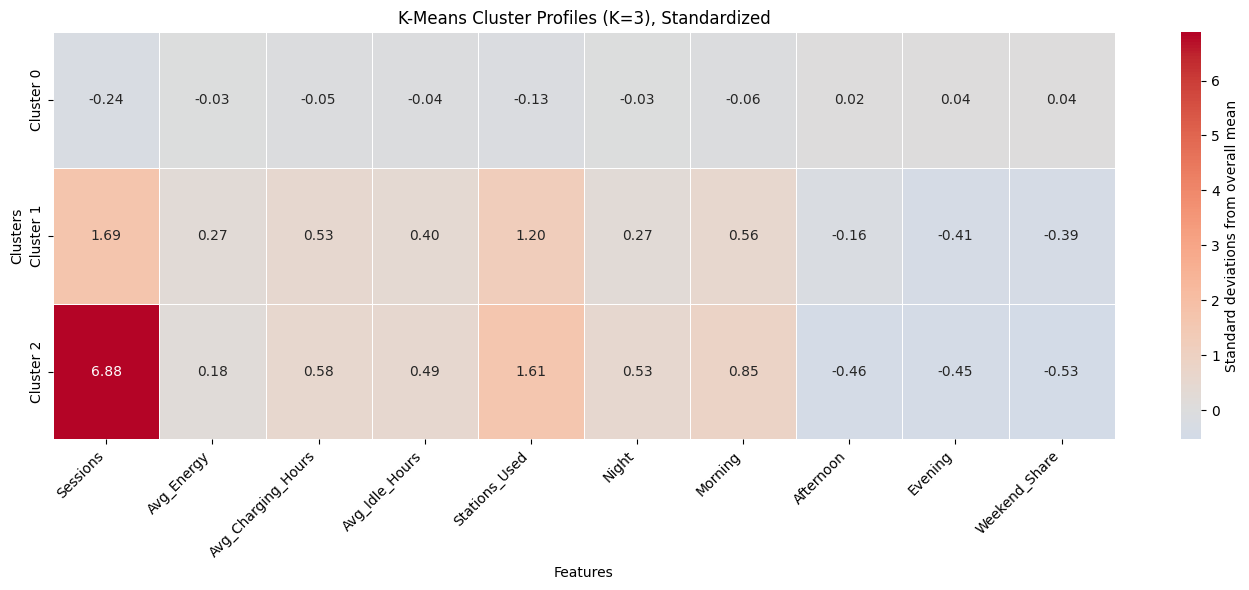

In [ ]:
X = users[features].copy()
cluster_centres = pd.DataFrame(
    kmeans3.cluster_centers_,
    columns=features,
    index=["Cluster 0", "Cluster 1", "Cluster 2"]
)

# Standardize each feature using the overall mean/std of the data
centres_z = (cluster_centres - X.mean()) / X.std()

plt.figure(figsize=(14, 6))
sns.heatmap(
    centres_z,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "Standard deviations from overall mean"}
)
plt.title("K-Means Cluster Profiles (K=3), Standardized")
plt.xlabel("Features")
plt.ylabel("Clusters")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# CONCLUSION:

## Comparison of Energy Consumption and Charger Occupation

The three clusters exhibit different behaviours in terms of energy consumption, charging duration and charger occupation.

Cluster 0 has the lowest average energy consumption per session (7.64 kWh), the shortest average charging duration (1.68 hours), and the shortest average idle duration (0.31 hours). Its average values are relatively close to the overall average in the standardised heatmap, although its energy consumption, charging duration and idle duration are slightly below the average. This suggests that these users generally have shorter charging sessions and occupy chargers for less time after charging has finished.

Clusters 1 and 2 show higher average energy consumption per session (9.18 kWh and 8.74 kWh, respectively), as well as longer charging durations (2.22 and 2.26 hours). Their idle durations are also higher (0.59 and 0.65 hours). The standardised heatmap confirms that both clusters are above the overall average for charging duration and idle time.

An interesting distinction is that Cluster 2 has the longest average charging and idle durations, despite having slightly lower average energy consumption than Cluster 1. This suggests that longer charger occupation does not necessarily correspond to higher energy consumption. In particular, users in Cluster 2 may leave their vehicles connected for longer after charging has finished.

Overall, these findings highlight the importance of distinguishing between energy consumption and charger occupation. They represent different aspects of user behaviour and may have different implications for the company's charging infrastructure.

## Comparison of Clusters and Weekend vs. Weekday Behaviour

The standardised heatmap reveals three different user profiles, particularly in terms of charging frequency, station usage and preferred charging periods.

**Cluster 0 – Lower-frequency users with relatively balanced usage**

Cluster 0 has the lowest average number of charging sessions (18.97) and uses an average of 5.34 different charging stations. Its standardised values are generally close to zero, meaning that most of its behavioural characteristics are relatively close to the average across clusters.

Regarding charging periods, afternoon usage represents the largest share (46%), followed by evening (32%) and morning (21%). Night-time usage is almost nonexistent (1%). This cluster also has the highest weekend energy share, at 31%.

These users can therefore be characterised as relatively infrequent customers, with a stronger tendency towards afternoon and weekend charging.

**Cluster 1 – Frequent users with predominantly daytime charging behaviour**

Cluster 1 has an average of 171.84 charging sessions, considerably above Cluster 0. Its standardised Sessions value (1.69) indicates that its average charging frequency is substantially above the average across the three clusters. It also has a relatively high number of stations used (10.04).

The cluster shows above-average energy consumption, charging duration and idle duration. Its charging activity is concentrated in the morning (36%) and afternoon (42%), while evening usage accounts for 19% and night-time usage for only 3%.

Its weekend energy share is 19%, below that of Cluster 0. The standardised heatmap also shows below-average afternoon, evening and weekend shares, although morning activity is above average.

This group can be characterised as frequent users with predominantly daytime charging behaviour and relatively low weekend activity.

**Cluster 2 – Very frequent users with the highest overall activity**

Cluster 2 is the most active group, with an average of 581.87 charging sessions and 11.51 different stations used. Its standardised Sessions value (6.88) is particularly high, indicating that its average charging frequency is substantially greater than that of the other clusters.

This group also has above-average charging duration, idle duration and energy consumption. Its usage is concentrated in the morning (43%) and afternoon (34%), with evening usage accounting for 18%. Night-time usage is slightly higher than in the other clusters, at 5%.

However, Cluster 2 has the lowest weekend energy share (15%). The standardised heatmap confirms that its weekend share is below the overall average (-0.53), as are its afternoon and evening shares.

These users can be characterised as highly active customers who predominantly use the charging network during weekdays, particularly in the morning.

## General Evaluation of the K-Means Clustering

The K-Means algorithm identified three groups with distinct charging behaviours. The standardised heatmap makes it easier to compare these groups because it removes the differences in measurement scales between the features.

The most noticeable distinction is charging frequency. Cluster 2 has a particularly high number of charging sessions, followed by Cluster 1, while Cluster 0 has considerably fewer sessions. The number of charging stations used follows a similar pattern, suggesting that the more frequent users also tend to use a wider range of stations.

The clusters also differ in their preferred charging periods and weekend activity. Cluster 0 has the highest weekend energy share (31%), while Cluster 2 has the lowest (15%). Cluster 1 and Cluster 2 show stronger morning activity, whereas Cluster 0 has a higher afternoon and evening share.

The results also demonstrate that charging frequency, energy consumption and charger occupation are not interchangeable measures. For example, Cluster 2 has the highest charging frequency and longest average occupation, but Cluster 1 has slightly higher average energy consumption per session.

Overall, the clustering provides a useful segmentation of the customer base based on historical charging behaviour.


# 5. TASK 2: ENERGY PREDICTION

# 5.1 Train and test split

In [ ]:
hourly["Day of Week"] = hourly["Hour"].dt.dayofweek
hourly["Hour of Day"] = hourly["Hour"].dt.hour

cutoff = hourly["Hour"].quantile(0.7)
train = hourly[hourly["Hour"] <= cutoff]
test = hourly[hourly["Hour"] > cutoff]

print("Cutoff:", cutoff)
print("Train rows:", len(train))
print("Test rows: ", len(test))

Cutoff: 2018-03-07 19:00:00
Train rows: 2721864
Test rows:  1166493


The split is chronological rather than random. Shuffling would let the model learn from hours that come after the ones it is tested on, which is not available in a real forecasting setting and would overstate performance.

# 5.2 Naive baseline

In [ ]:
profile = (
    train.groupby(["Station Name", "Day of Week", "Hour of Day"], as_index=False)["Hourly Energy (kWh)"]
         .mean()
         .rename(columns={"Hourly Energy (kWh)": "Prediction"})
)

test = test.merge(profile, on=["Station Name", "Day of Week", "Hour of Day"], how="left")
test["Prediction"] = test["Prediction"].fillna(train["Hourly Energy (kWh)"].mean())

error = test["Hourly Energy (kWh)"] - test["Prediction"]
mae = error.abs().mean()
rmse = np.sqrt((error ** 2).mean())

print("Baseline MAE: ", round(mae, 4))
print("Baseline RMSE:", round(rmse, 4))

Baseline MAE:  0.88
Baseline RMSE: 1.8616


The baseline predicts each hour using the average of the same weekday and hour of the day at the same station, estimated on the training period only. It captures the daily and weekly cycle without any model fitting, which makes it the natural reference point.

**Baseline MAE 0.88 kWh and RMSE 1.86 kWh.** Any model proposed for the prediction task has to beat these figures on the same split to be worth keeping.